# Mustafa Abbas Abokhadher
# 2240002889
# 7MA2

# Lab 6
**ARTI403 – Image Processing**

* Task 1 (Procedural): Laplacian filter in the frequency domain
* Task 1 (Assessment): Sobel filters in the frequency domain

## Procedural Task #1: Filtering in the Frequency Domain (Laplacian)

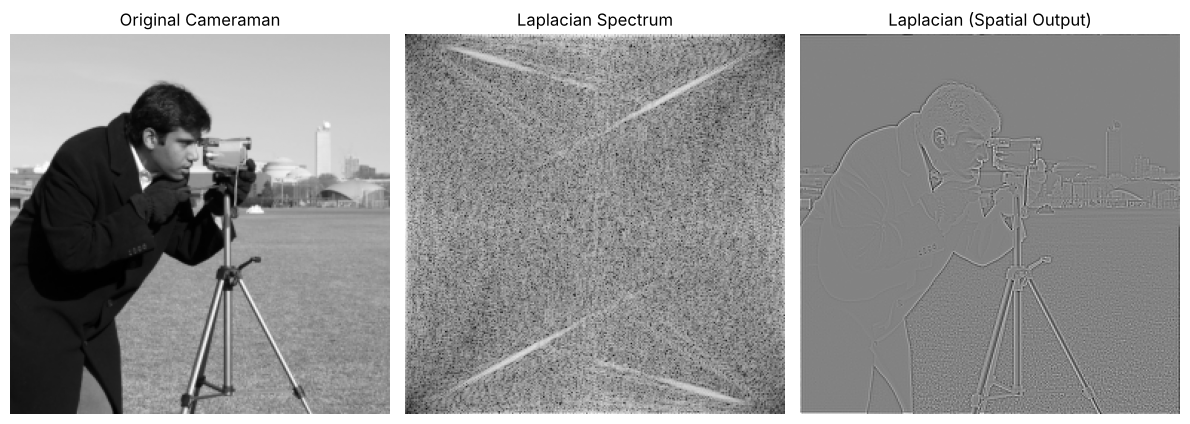

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from numpy.fft import fft2, ifft2, fftshift, ifftshift

# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))  # Resize for faster FFT (optional)

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1); plt.imshow(image, cmap='gray'); plt.title('Original Cameraman'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray'); plt.title('Laplacian Spectrum'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(laplacian_image, cmap='gray'); plt.title('Laplacian (Spatial Output)'); plt.axis('off')
plt.tight_layout()
plt.show()

## Assessment Task #1: Sobel filters in the frequency domain (Cameraman)

**Idea:** convolution in the spatial domain = multiplication in the frequency domain. So we (1) pad the 3×3 Sobel kernel to the image size, (2) move its centre to (0,0) with `ifftshift`, (3) take its FFT, (4) multiply with the image FFT, (5) inverse FFT.

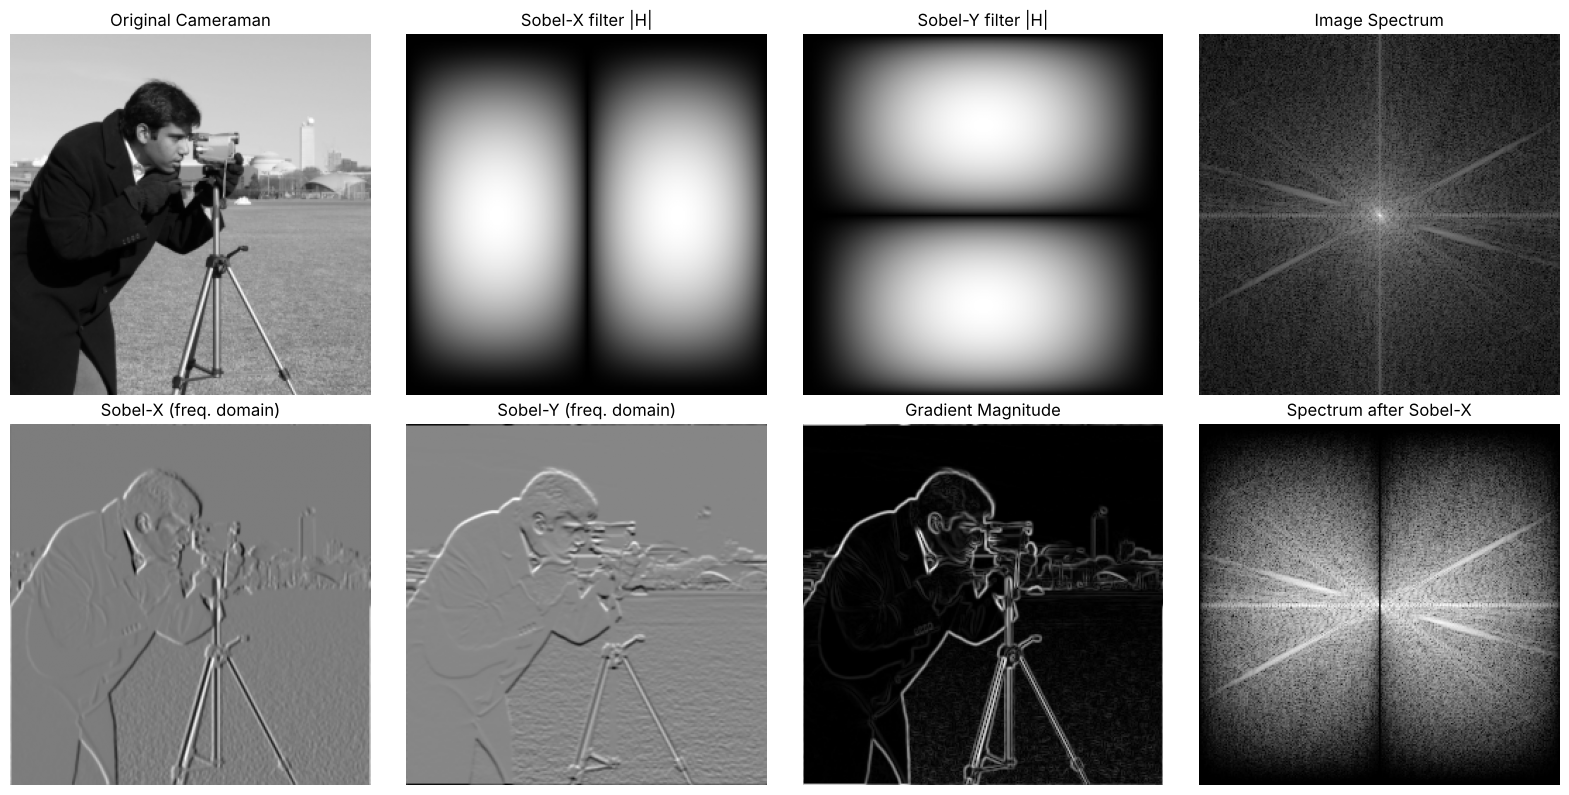

In [2]:
# Load and resize image
image = data.camera()
image = resize(image, (256, 256))
M, N = image.shape

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# Compute FFT of image
F_img = fft2(image)

# FFT of centered Sobel filters (use the provided function)
H_x = center_embed_kernel(sobel_x, (M, N))
H_y = center_embed_kernel(sobel_y, (M, N))

# Multiply in the frequency domain
G_x = F_img * H_x
G_y = F_img * H_y

# Inverse FFT -> spatial results
gx = ifft2(G_x).real
gy = ifft2(G_y).real
magnitude = np.sqrt(gx**2 + gy**2)   # gradient magnitude (edge strength)

# Plot
plt.figure(figsize=(16, 8))
plt.subplot(2, 4, 1); plt.imshow(image, cmap='gray'); plt.title('Original Cameraman'); plt.axis('off')
plt.subplot(2, 4, 2); plt.imshow(np.log(1 + np.abs(fftshift(H_x))), cmap='gray'); plt.title('Sobel-X filter |H|'); plt.axis('off')
plt.subplot(2, 4, 3); plt.imshow(np.log(1 + np.abs(fftshift(H_y))), cmap='gray'); plt.title('Sobel-Y filter |H|'); plt.axis('off')
plt.subplot(2, 4, 4); plt.imshow(np.log(1 + np.abs(fftshift(F_img))), cmap='gray'); plt.title('Image Spectrum'); plt.axis('off')
plt.subplot(2, 4, 5); plt.imshow(gx, cmap='gray'); plt.title('Sobel-X (freq. domain)'); plt.axis('off')
plt.subplot(2, 4, 6); plt.imshow(gy, cmap='gray'); plt.title('Sobel-Y (freq. domain)'); plt.axis('off')
plt.subplot(2, 4, 7); plt.imshow(magnitude, cmap='gray'); plt.title('Gradient Magnitude'); plt.axis('off')
plt.subplot(2, 4, 8); plt.imshow(np.log(1 + np.abs(fftshift(G_x))), cmap='gray'); plt.title('Spectrum after Sobel-X'); plt.axis('off')
plt.tight_layout()
plt.show()

### Verification against spatial-domain filtering
The frequency-domain result must match true (circular) convolution in the spatial domain.

In [3]:
from scipy.ndimage import convolve
# True 2D convolution with circular (wrap) borders - exactly what multiplication in the FFT domain does
ref_x = convolve(image, sobel_x.astype(np.float64), mode='wrap')
ref_y = convolve(image, sobel_y.astype(np.float64), mode='wrap')
print("Max difference Sobel-X :", np.abs(gx - ref_x).max())
print("Max difference Sobel-Y :", np.abs(gy - ref_y).max())

Max difference Sobel-X : 1.4883927423881005e-15
Max difference Sobel-Y : 2.8380076066980564e-15


### Observations
* **Sobel-X** responds to *vertical* edges (intensity changes left→right); **Sobel-Y** responds to *horizontal* edges.
* In the frequency domain Sobel is a **high-pass** filter in one direction combined with a smoothing (low-pass) in the perpendicular direction – its spectrum is zero at the DC component, so flat regions become 0 (gray).
* The gradient magnitude √(Gx²+Gy²) combines both and gives the complete edge map.
* The difference with the spatial result is ~1e-15, i.e. the two methods are equivalent.